In [17]:
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix,precision_score, recall_score,f1_score,roc_curve, roc_auc_score

filename = r"exoplanets_slim_2026-11-3.csv"

df = pd.read_csv(
    filename,
    header=0
)

# making columns titles more readable
df = df.rename(columns={
    "pl_name": "pl_name",
    "hostname": "host_name",

    "sy_snum": "sys_num_star",
    "sy_pnum": "sys_num_planet",
    "sy_dist": "sys_dist_e",

    "discoverymethod": "disc_method",
    #"disc_year": "",
    #"disc_facility": "",

    #"pl_controv_flag": "",
    "pl_eqt": "pl_temp",
    "pl_insol": "pl_insol_flux",

    "pl_orbper": "pl_orb_period",
    "pl_orbeccen": "pl_orb_eccen",
    "pl_orbsmax": "pl_orb_semimajor_axis",

    "pl_rade": "pl_radius_e",
    "pl_bmasse": "pl_mass_e",
    "pl_bmassprov": "pl_mass_prov",

    "st_teff": "st_temp",
    "st_rad": "st_radius",
    #"st_mass": "",
    "st_met": "st_metal",
    "st_logg": "st_gravity",
    #"st_age": "",
    })

print(df.shape)
print(df.dtypes)

(6451, 23)
pl_name                      str
host_name                    str
sys_num_star               int64
sys_num_planet             int64
sys_dist_e               float64
disc_method                  str
disc_year                  int64
disc_facility                str
pl_controv_flag            int64
pl_temp                  float64
pl_insol_flux            float64
pl_orb_period            float64
pl_orb_eccen             float64
pl_orb_semimajor_axis    float64
pl_radius_e              float64
pl_mass_e                float64
pl_mass_prov                 str
st_temp                  float64
st_radius                float64
st_mass                  float64
st_metal                 float64
st_gravity               float64
st_age                   float64
dtype: object


In [18]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

d = df[["sys_num_planet", "pl_temp", "pl_mass_e",
        "pl_orb_period", "pl_radius_e"]].dropna()

X = d[["pl_temp", "pl_orb_period", "pl_radius_e"]]

y = (d["sys_num_planet"] > 1).astype(int)

print(y.value_counts())
print(y.value_counts(normalize=True) * 100)



sys_num_planet
0    3275
1    2507
Name: count, dtype: int64
sys_num_planet
0    56.641301
1    43.358699
Name: proportion, dtype: float64


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=29, stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.6002766251728907
              precision    recall  f1-score   support

           0       0.65      0.65      0.65       819
           1       0.54      0.53      0.53       627

    accuracy                           0.60      1446
   macro avg       0.59      0.59      0.59      1446
weighted avg       0.60      0.60      0.60      1446



sys_num_planet
0    819
1    627
Name: count, dtype: int64
[0 0 1 ... 1 1 0]


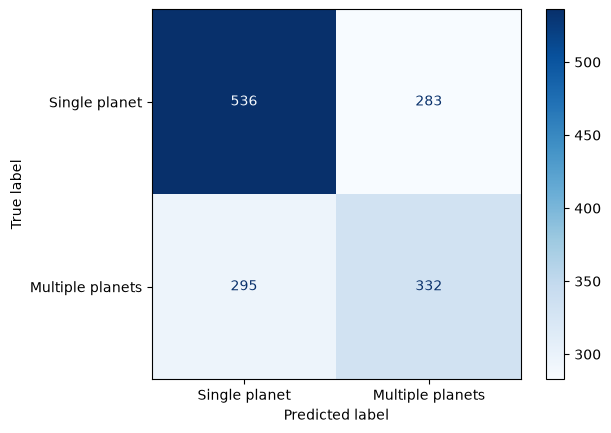

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Single planet", "Multiple planets"]
)

print(y_test.value_counts())
print(y_pred)

display.plot(cmap="Blues")
plt.show()

In [21]:
y_prob = model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", auc)

ROC-AUC: 0.6641954536691378


Accuracy: 0.7686453576864536
              precision    recall  f1-score   support

           0       0.78      0.86      0.82       782
           1       0.75      0.64      0.69       532

    accuracy                           0.77      1314
   macro avg       0.77      0.75      0.75      1314
weighted avg       0.77      0.77      0.76      1314

pl_orb_eccen
0    782
1    532
Name: count, dtype: int64
[0 0 0 ... 0 1 0]


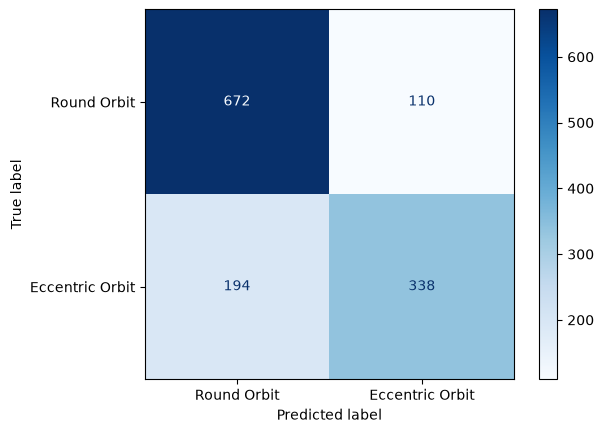

In [30]:
d = df[[
    "pl_orb_eccen",
    "pl_temp",
    "pl_mass_e",
    "pl_orb_period",
    "pl_radius_e"
]].dropna()

y = (d["pl_orb_eccen"] > 0).astype(int)

X = d[[
    "pl_temp",
    "pl_mass_e",
    "pl_orb_period",
    "pl_radius_e"
]]

def doClassification(X, y):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=29, stratify=y
    )

    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Round Orbit", "Eccentric Orbit"]
    )

    print(y_test.value_counts())
    print(y_pred)

    display.plot(cmap="Blues")
    plt.show()

doClassification(X, y)

Accuracy: 0.7534246575342466
              precision    recall  f1-score   support

           0       0.75      0.89      0.82       801
           1       0.76      0.53      0.63       513

    accuracy                           0.75      1314
   macro avg       0.76      0.71      0.72      1314
weighted avg       0.76      0.75      0.74      1314

pl_orb_eccen
0    801
1    513
Name: count, dtype: int64
[0 0 0 ... 1 0 0]


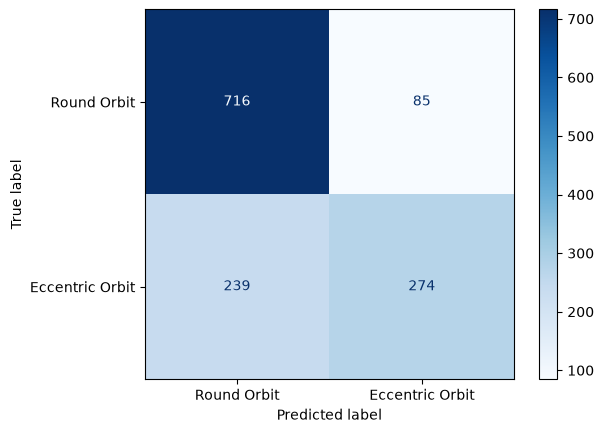

Accuracy: 0.7853881278538812
              precision    recall  f1-score   support

           0       0.79      0.92      0.85       849
           1       0.78      0.55      0.64       465

    accuracy                           0.79      1314
   macro avg       0.78      0.73      0.75      1314
weighted avg       0.78      0.79      0.77      1314

pl_orb_eccen
0    849
1    465
Name: count, dtype: int64
[0 0 0 ... 0 1 0]


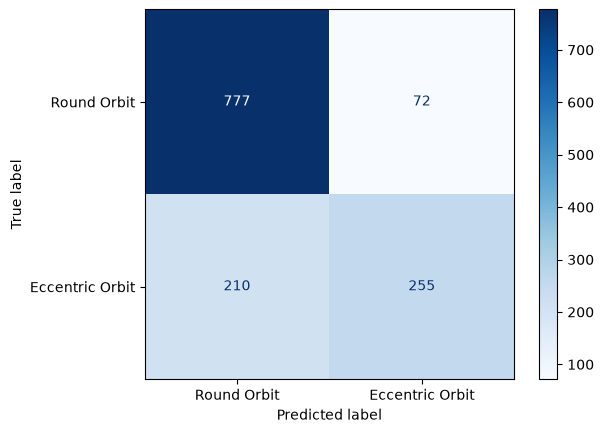

Accuracy: 0.845509893455099
              precision    recall  f1-score   support

           0       0.86      0.96      0.91      1014
           1       0.77      0.46      0.57       300

    accuracy                           0.85      1314
   macro avg       0.82      0.71      0.74      1314
weighted avg       0.84      0.85      0.83      1314

pl_orb_eccen
0    1014
1     300
Name: count, dtype: int64
[0 0 0 ... 0 1 0]


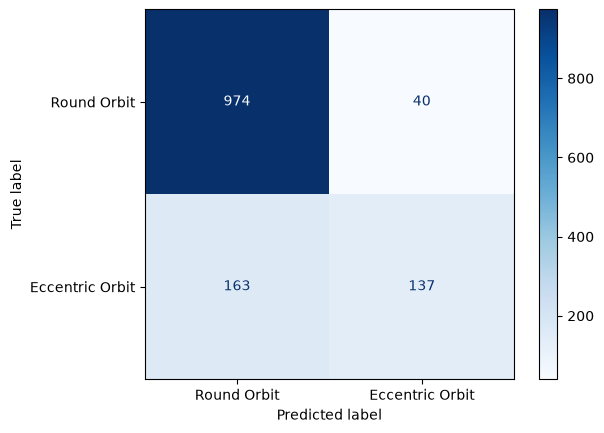

In [33]:
y = (d["pl_orb_eccen"] > 0.01).astype(int)
doClassification(X, y)

y = (d["pl_orb_eccen"] > 0.03).astype(int)
doClassification(X, y)

y = (d["pl_orb_eccen"] > 0.1).astype(int)
doClassification(X, y)
